# Behavioural analysis 001

## Imports

In [1]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.append('../../')

In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import pyaldata as pyal
import tools.dsp as dsp
from tools.params import Params
import tools.dataTools as dt
import tools.kinematics as kin
import tools.viz.utilityTools as vizutils

import bhv
from bhv import ACCENT, ANGLE_COLOR, DIM_COLOR, GROUP_COLOR, LEVEL_STYLE, NEUTRAL

## Caching

In [3]:
# Set this to be outside the repo
CACHE = Path("/mnt/mouse-data-london/proc") / "cache" / "bhv"
CACHE.mkdir(parents=True, exist_ok=True)

ALL_SESSIONS = [
    "M061_2025_03_04_10_00",
    "M061_2025_03_05_14_00",
    "M061_2025_03_06_14_00",
    "M062_2025_03_20_14_00",
    "M062_2025_03_21_14_00",
    "M063_2025_03_13_14_00",
    "M063_2025_03_14_15_30",
    "M078_2025_08_06_15_00",
    "M086_2025_12_10_15_00",
    "M103_2026_02_18_15_30",
    "M103_2026_02_19_15_30",  # less trials
    "M106_2026_02_25_15_00",
    # "M106_2026_02_26_16_00",  # less trials, currently no bhv
]

def build(sess):
    f = CACHE / f"{sess}.npz"
    if f.exists():
        return dict(np.load(f, allow_pickle=True))
    print(f'\n--------------------- {sess} ---------------------')
    td = dsp.load_and_preprocess_trials_from_sess(
            sess, std=0.03, run_pca=False, 
        )
    td = dsp.drop_unperturbed_or_stopped_trials(td)                      
    td = pyal.restrict_to_interval(td, start_point_name="idx_sol_on", rel_start=-200, rel_end=200)
    td = dt.add_bhv(td, bhv_fields=Params.pos_keypoints)
    td, _, _ = kin.rotate_bhv_td(td)
    codes = np.array(td.values_Sol_direction.tolist()).ravel()
    out = dict(
        bhv=np.stack(td.bhv), bhv_rot=np.stack(td.bhv_rot), codes=codes,
        side=np.vectorize(Params.sol_dir_to_contra_ipsi.get)(codes),
        level=np.vectorize(Params.sol_dir_to_level.get)(codes),
        angle=np.vectorize(Params.sol_dir_to_angle.get)(codes),
        perturb_phase=np.stack(td.phase_at_perturb), perturb_score=np.stack(td.perturb_score),
        perturb_score_log_sum=td.perturb_score_log_sum.values, 
        bhv_keypoints=np.array(Params.pos_keypoints), phase_keypoints=np.array(Params.oscillating_keypoints),
        trial_id=td.trial_id.values, window=np.array([-200, 200]),
    )
    np.savez(f, **out)
    return out

### Build cache

In [28]:
# Build cache
s = {sess: build(sess) for sess in ALL_SESSIONS}

--------------------- M061_2025_03_04_10_00 ---------------------

##### Loading and preprocessing ######


/root/repos/pyaldata/pyaldata/data_cleaning.py:120: UserWarning: fields: ['values_before_camera_trigger', 'idx_before_camera_trigger'] could not be converted to int.
  utils.warnings.warn(f"fields: {bad_fields} could not be converted to int.")
/root/repos/pyaldata/pyaldata/data_cleaning.py:120: UserWarning: fields: ['idx_motion'] could not be converted to int.
  utils.warnings.warn(f"fields: {bad_fields} could not be converted to int.")
/root/repos/pyaldata/pyaldata/data_cleaning.py:120: UserWarning: fields: ['values_Sol_direction', 'idx_Sol_direction', 'values_Sol_duration', 'idx_Sol_duration', 'idx_sol_on'] could not be converted to int.
  utils.warnings.warn(f"fields: {bad_fields} could not be converted to int.")
/root/repos/pyaldata/pyaldata/utils.py:164: UserWarning: values_MotSen1_X might be a time-varying field. It matches the length of all_spikes on 99.8529411764706% of trials
  warnings.warn(
/root/repos/pyaldata/pyaldata/utils.py:164: UserWarning: idx_MotSen1_X might be a tim

['all_spikes', 'VAL_spikes', 'SSp_spikes', 'GPe_spikes', 'MOp_spikes', 'CP_spikes']
Resulting all_spikes ephys data shape is (NxT): (53, 60000)
Resulting VAL_spikes ephys data shape is (NxT): (240, 60000)
Resulting SSp_spikes ephys data shape is (NxT): (59, 60000)
Resulting GPe_spikes ephys data shape is (NxT): (112, 60000)
Resulting MOp_spikes ephys data shape is (NxT): (206, 60000)
Resulting CP_spikes ephys data shape is (NxT): (225, 60000)

##### Dropping unsteady running trials ######
bhv column not found, adding it
otsu immobility threshold: 2.2328
drop_unsteady_running_trials: dropping 63 of 339 trials (18.6%)
  below otsu speed thresh: 20  |  cv > 0.255: 61  |  both: 18  |  speed only: 2  |  cv only: 43

##### Calculating perturbation metric ######
bhv field already present, overwriting it
compute_power_in_bhv_concat_td: dropping 22 trial(s) with peak_mean_freq < 2 Hz
  drop_unperturbed_trials: dropped by stat=sem: 41  |  dropped by value: 0  |  kept: 213/254 (83.9%)


/root/repos/earthquake-analysis/notebooks/_clean/../../tools/dsp/preprocessing.py:95: RuntimeWarning: divide by zero encountered in log10
  ``_insert_nans_and_extend_to_spikes_shape_inplace``), padding to


  [frame] L/R ml separation: +8.49 (paws), +11.65 (feet); ml dominance 3.9x / 12.1x (needs > 2.0)
  [frame] stride sd [rc,vt,ml] left_paw=[4.68, 1.13, 2.27] right_foot=[7.17, 2.19, 3.35]  (rc dominant, as required)
  [frame] yaw -148.7 +- 6.0 deg (circular; R=0.995); limbs below hip on vt: True
--------------------- M061_2025_03_05_14_00 ---------------------

##### Loading and preprocessing ######


...

['CP_spikes', 'all_spikes', 'MOp_spikes', 'SSp_spikes', 'VAL_spikes']
Resulting CP_spikes ephys data shape is (NxT): (176, 120000)
Resulting all_spikes ephys data shape is (NxT): (9, 120000)
Resulting MOp_spikes ephys data shape is (NxT): (141, 120000)
Resulting SSp_spikes ephys data shape is (NxT): (92, 120000)
Resulting VAL_spikes ephys data shape is (NxT): (229, 120000)

##### Dropping unsteady running trials ######
bhv column not found, adding it
otsu immobility threshold: 2.6853
drop_unsteady_running_trials: dropping 19 of 267 trials (7.1%)
  below otsu speed thresh: 15  |  cv > 0.255: 18  |  both: 14  |  speed only: 1  |  cv only: 4

##### Calculating perturbation metric ######
bhv field already present, overwriting it
compute_power_in_bhv_concat_td: dropping 7 trial(s) with peak_mean_freq < 2 Hz
  drop_unperturbed_trials: dropped by stat=sem: 103  |  dropped by value: 0  |  kept: 138/241 (57.3%)
  [frame] L/R ml separation: +9.03 (paws), +13.91 (feet); ml dominance 5.1x / 10.1x 

/root/repos/earthquake-analysis/notebooks/_clean/../../tools/dsp/preprocessing.py:95: RuntimeWarning: divide by zero encountered in log10
  ``_insert_nans_and_extend_to_spikes_shape_inplace``), padding to


--------------------- M106_2026_02_25_15_00 ---------------------

##### Loading and preprocessing ######


/root/repos/pyaldata/pyaldata/data_cleaning.py:120: UserWarning: fields: ['values_before_camera_trigger', 'idx_before_camera_trigger', 'values_Sol_duration', 'values_Sol_direction'] could not be converted to int.
  utils.warnings.warn(f"fields: {bad_fields} could not be converted to int.")
/root/repos/pyaldata/pyaldata/data_cleaning.py:120: UserWarning: fields: ['values_before_camera_trigger', 'values_Sol_duration', 'idx_Sol_duration', 'values_Sol_direction', 'idx_Sol_direction', 'idx_sol_on'] could not be converted to int.
  utils.warnings.warn(f"fields: {bad_fields} could not be converted to int.")
/root/repos/pyaldata/pyaldata/data_cleaning.py:120: UserWarning: fields: ['values_before_camera_trigger', 'values_Sol_duration', 'idx_Sol_duration', 'values_Sol_direction', 'idx_Sol_direction', 'idx_sol_on'] could not be converted to int.
  utils.warnings.warn(f"fields: {bad_fields} could not be converted to int.")
/root/repos/pyaldata/pyaldata/utils.py:164: UserWarning: values_MotSen1_X m

['CP_spikes', 'MOp_spikes', 'all_spikes', 'VAL_spikes', 'SSp_spikes']
Resulting CP_spikes ephys data shape is (NxT): (206, 48000)
Resulting MOp_spikes ephys data shape is (NxT): (156, 48000)
Resulting all_spikes ephys data shape is (NxT): (11, 48000)
Resulting VAL_spikes ephys data shape is (NxT): (132, 48000)
Resulting SSp_spikes ephys data shape is (NxT): (142, 48000)

##### Dropping unsteady running trials ######
bhv column not found, adding it
otsu immobility threshold: 2.2123
drop_unsteady_running_trials: dropping 147 of 500 trials (29.4%)
  below otsu speed thresh: 42  |  cv > 0.255: 147  |  both: 42  |  speed only: 0  |  cv only: 105

##### Calculating perturbation metric ######
bhv field already present, overwriting it
add_concat_perturb_time: dropping 1 trial(s) with missing idx_sol_on
compute_power_in_bhv_concat_td: dropping 30 trial(s) with peak_mean_freq < 2 Hz
  drop_unperturbed_trials: dropped by stat=sem: 96  |  dropped by value: 6  |  kept: 220/322 (68.3%)
  [frame] L/R

### Load cache

In [4]:
def load_bhv_cache(sessions=ALL_SESSIONS, cache_dir=CACHE, fields=None):
    missing = [s for s in sessions if not (cache_dir / f"{s}.npz").exists()]
    if missing:
        raise FileNotFoundError(f"No cache for {missing} in {cache_dir} -- build it first")

    out = {}
    for sess in sessions:
        with np.load(cache_dir / f"{sess}.npz", allow_pickle=False) as z:
            keys = fields if fields is not None else z.files
            out[sess] = {k: z[k] for k in keys}
    return out

s = load_bhv_cache()

## Single trial: xyz of all keypoints

In [120]:
sess, trial = "M061_2025_03_06_14_00", 101
d = s[sess]
kps = list(d["bhv_keypoints"])
X = d["bhv"][trial].reshape(len(d["bhv"][trial]), -1, 3) 
t = (np.arange(len(X)) - 200) / 100                       

groups = {
    "forelimb": ["left_elbow", "left_wrist", "left_paw", "right_elbow", "right_wrist", "right_paw"],
    "hindlimb": ["left_knee", "left_ankle", "left_foot", "right_knee", "right_ankle", "right_foot"],
    "axial":    ["shoulder_center", "left_shoulder", "right_shoulder", "hip_center",
                 "tail_base", "tail_middle", "tail_tip"],
}
rows = [(kp, g) for g, kp_list in groups.items() for kp in kp_list]

<Figure size 640x480 with 0 Axes>

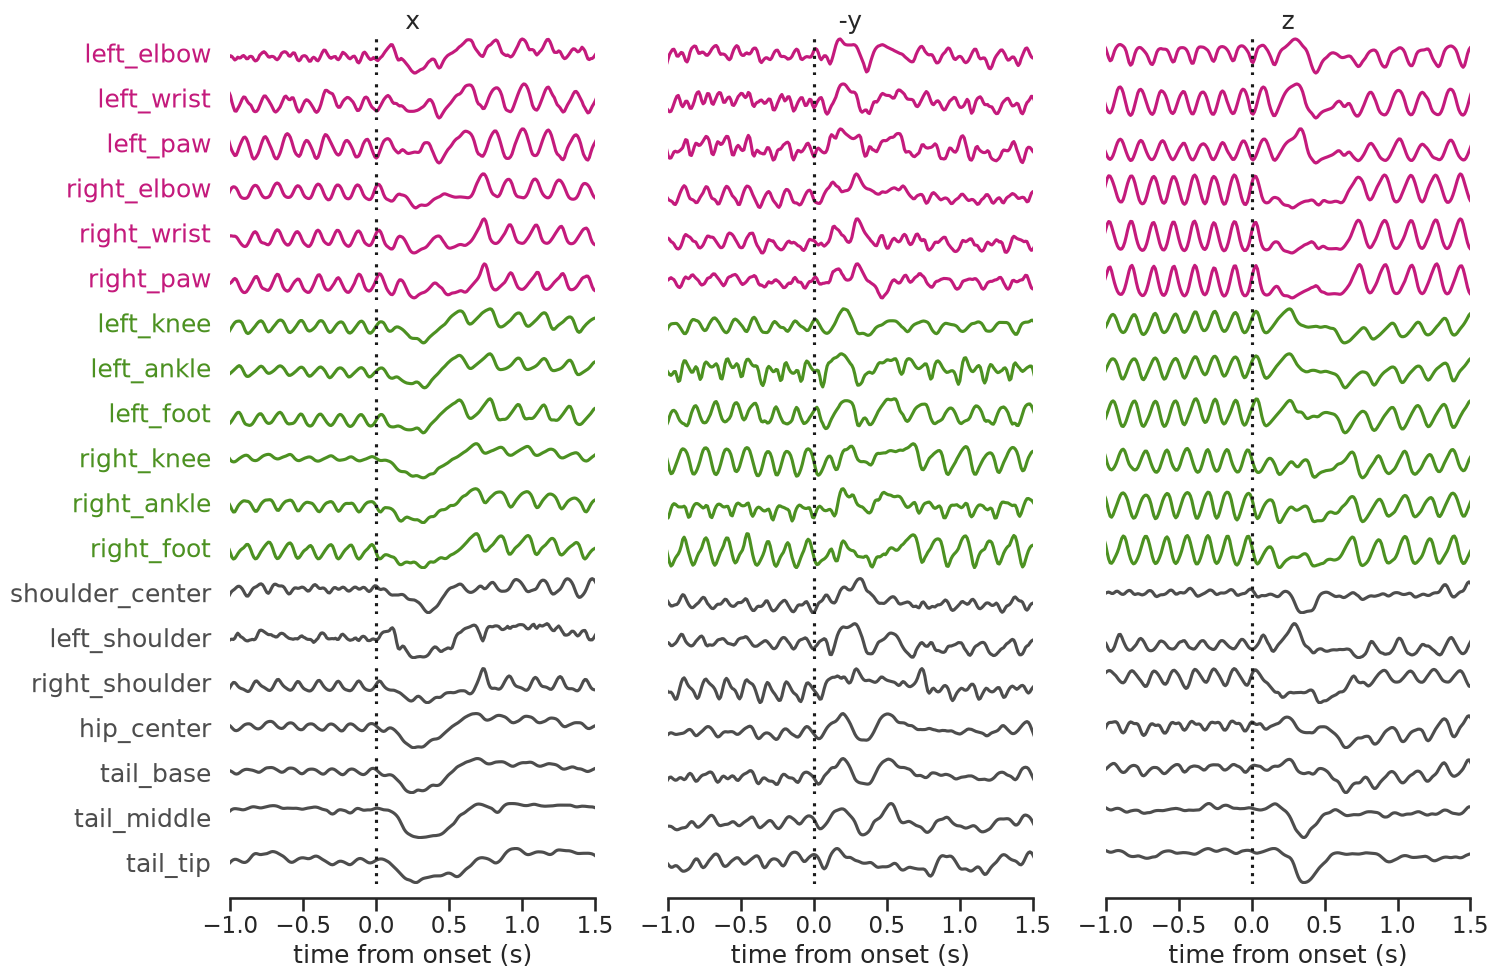

In [121]:
with vizutils.apply_plot_style('talk'):
    fig, axs = plt.subplots(len(rows), 3, figsize=(16, 11), sharex=True)
    for r, (kp, g) in enumerate(rows):
        for c in range(3):
            axs[r, c].plot(t, X[:, kps.index(kp), c], color=GROUP_COLOR[g])
            axs[r, c].set_yticks([])
        axs[r, 0].set_ylabel(kp, rotation=0, ha="right", va="center", color=GROUP_COLOR[g])
    for c, name in enumerate(["x", "-y", "z"]):
        axs[0, c].set_title(name)
        axs[-1, c].set_xlabel("time from onset (s)")
    axs[0, 0].set_xlim(-1, 1.5)

    for ax in fig.axes:
        ax.axvline(0, color="k", ls=":")

for ax in axs.ravel():  
    ax.spines["left"].set_visible(False)
for ax in axs[:-1].ravel():
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(bottom=False)
plt.show()

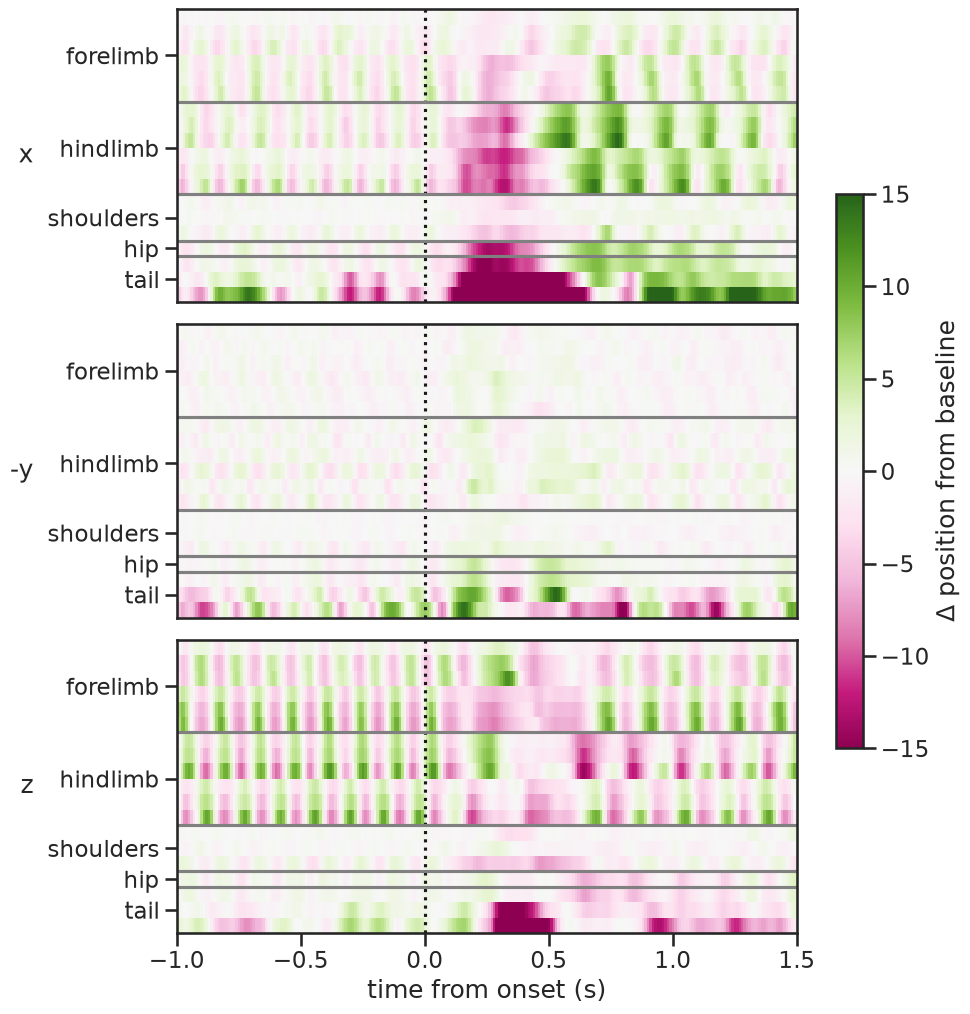

<Figure size 640x480 with 0 Axes>

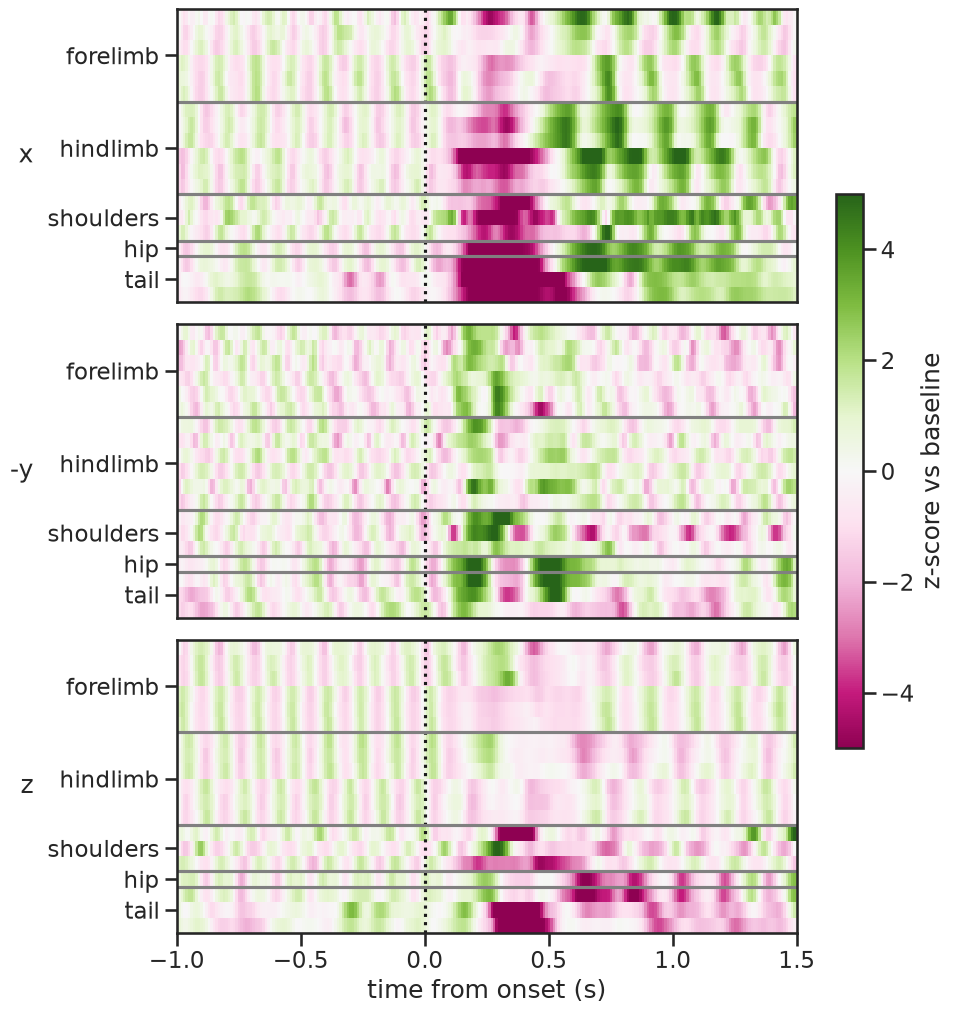

In [122]:
fig, axs = bhv.plot_trial_heatmap(X, t, kps, vmax=15)
fig, axs = bhv.plot_trial_heatmap(X, t, kps, vmax=5, zscore=True)

## Single session

<Figure size 640x480 with 0 Axes>

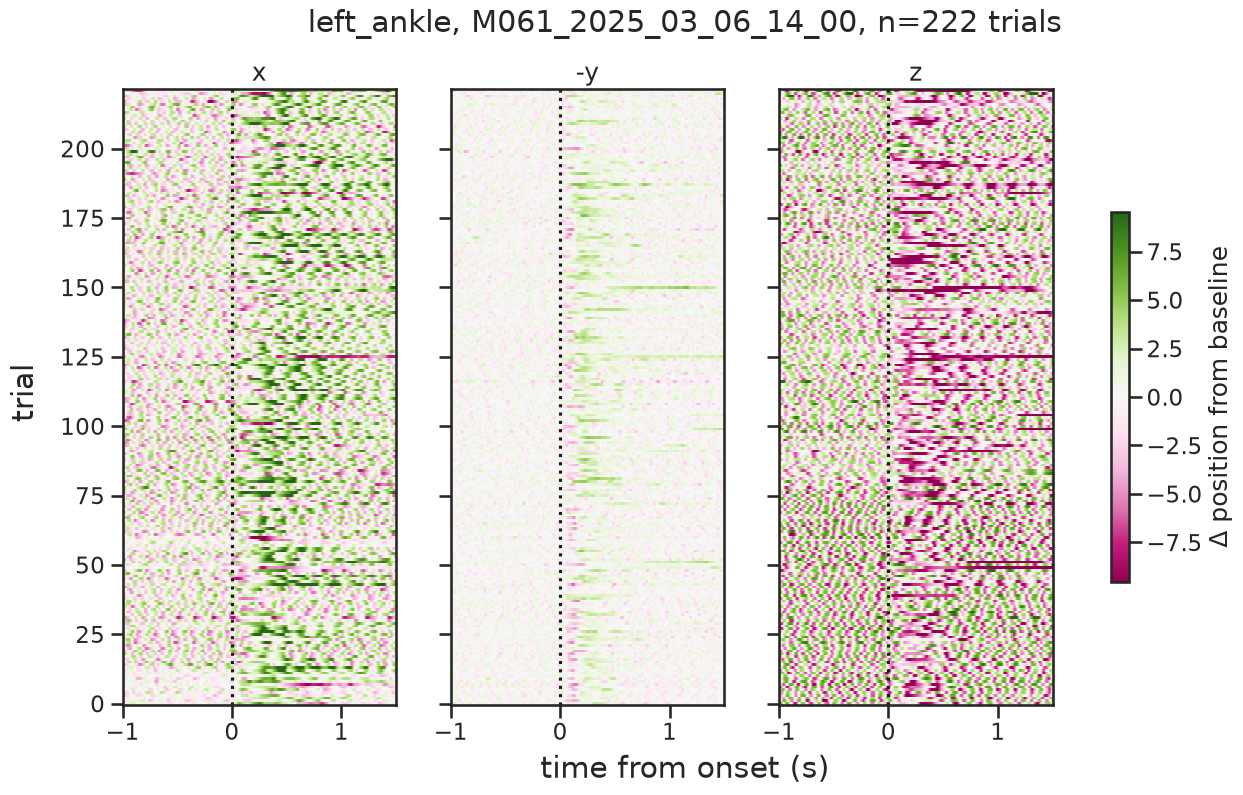

In [123]:
kp = "left_ankle"
B = s[sess]["bhv"].reshape(len(s[sess]["bhv"]), len(t), -1, 3)[:, :, kps.index(kp)]
B = B - B[:, t < 0].mean(axis=1, keepdims=True)
vmax = np.percentile(np.abs(B), 99)

with vizutils.apply_plot_style('talk'):

    fig, axs = plt.subplots(1, 3, figsize=(15, 8), sharex=True, sharey=True)
    for d, ax in enumerate(axs):
        im = ax.pcolormesh(t, np.arange(len(B)), B[:, :, d], cmap="PiYG",
                        vmin=-vmax, vmax=vmax, shading="nearest")
        ax.axvline(0, color="k", ls=":")
        ax.set_title(["x", "-y", "z"][d])
    axs[0].set_xlim(-1, 1.5)
    fig.supxlabel("time from onset (s)")
    fig.supylabel("trial", x=0.05)
    fig.colorbar(im, ax=axs, label="Δ position from baseline", shrink=0.6)
    fig.suptitle(f"{kp}, {sess}, n={len(B)} trials")
    plt.show()

<Figure size 640x480 with 0 Axes>

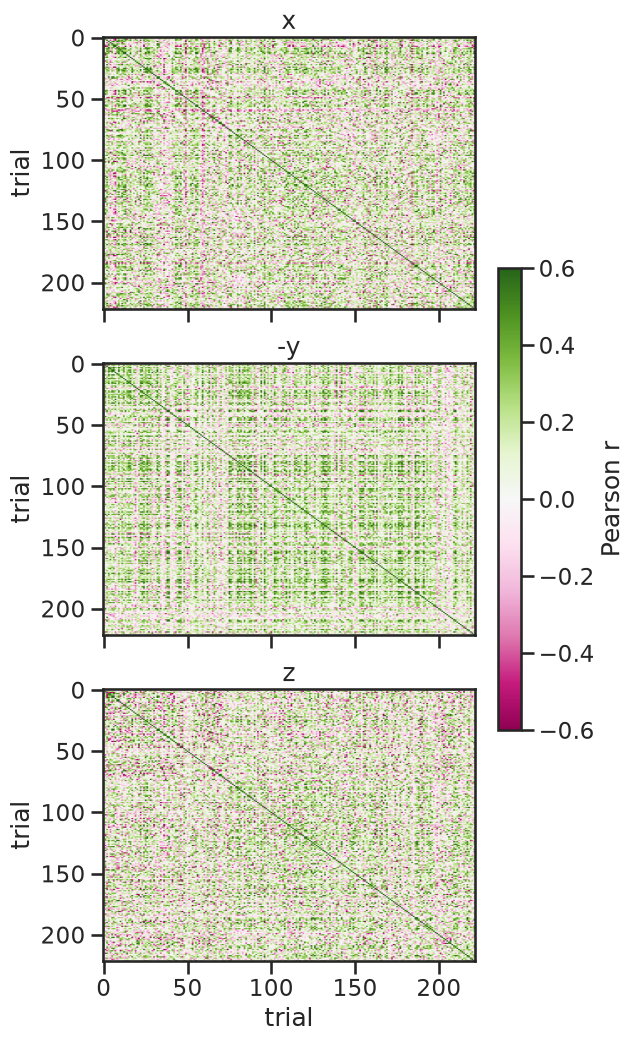

In [124]:
win = (t >= -1) & (t <= 1.5)
with vizutils.apply_plot_style('talk'):

    fig, axs = plt.subplots(3, 1, figsize=(6, 12), sharex=True, sharey=True)
    for d, ax in enumerate(axs):
        im = ax.imshow(np.corrcoef(B[:, win, d]), cmap="PiYG", vmin=-0.6, vmax=0.6, aspect='auto')
        ax.set_title(["x", "-y", "z"][d])
        ax.set_ylabel("trial")
    axs[-1].set_xlabel("trial")
    fig.colorbar(im, ax=axs, label="Pearson r", shrink=0.5)
    # fig.suptitle(f"{kp}, {sess}, n={len(B)} trials")
    plt.show()

## Exemplify rotation

<Figure size 640x480 with 0 Axes>

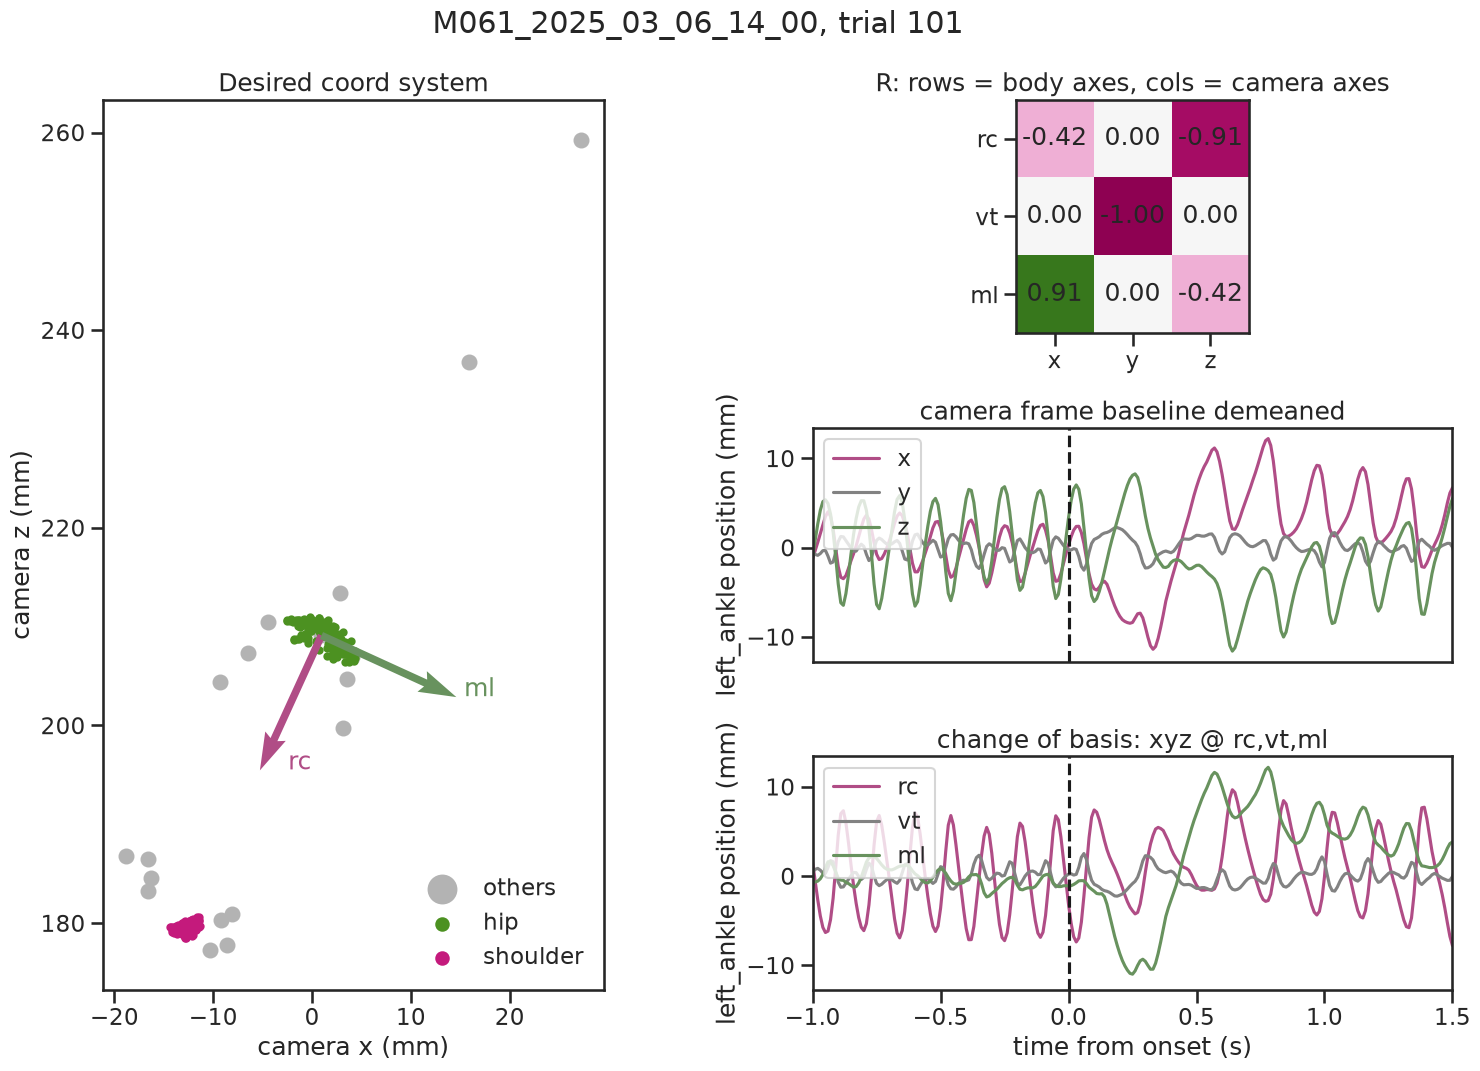

In [138]:
kp_ex = "left_ankle"
k = kps.index(kp_ex)
bs = (t >= -1.5) & (t < -0.1)

hip, sho = X[:, kps.index("hip_center")], X[:, kps.index("shoulder_center")]
rc = (sho[bs] - hip[bs]).mean(axis=0)
rc[1] = 0
rc /= np.linalg.norm(rc)
vt = np.array([0.0, -1.0, 0.0])
ml = np.cross(vt, rc)
R = np.stack([rc, vt, ml])

cam = X[:, k] - X[bs, k].mean(axis=0)
rot = s[sess]["bhv_rot"][trial].reshape(len(X), -1, 3)[:, k]
assert np.allclose(cam @ R.T, rot)

with vizutils.apply_plot_style('talk'):

    fig = plt.figure(figsize=(16, 11))
    gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1])

    ax = fig.add_subplot(gs[:, 0])
    base_mean = X[bs].mean(axis=0)
    ax.scatter(base_mean[:, 0], base_mean[:, 2], color="0.7", s=100, label="others")
    ax.scatter(*hip[bs][:, [0, 2]].T, color=GROUP_COLOR["hindlimb"], s=20, label="hip")
    ax.scatter(*sho[bs][:, [0, 2]].T, color=GROUP_COLOR["forelimb"], s=20, label="shoulder")
    h = hip[bs].mean(axis=0)
    ax.quiver(h[0], h[2], rc[0], rc[2], angles="xy", scale_units="xy", scale=1 / 15, color=DIM_COLOR[0], width=0.015)
    ax.quiver(h[0], h[2], ml[0], ml[2], angles="xy", scale_units="xy", scale=1 / 15, color=DIM_COLOR[2], width=0.015)
    ax.text(h[0] + 10 * rc[0], h[2] + 15 * rc[2], " rc", color=DIM_COLOR[0])
    ax.text(h[0] + 15 * ml[0], h[2] + 15 * ml[2], " ml", color=DIM_COLOR[2])
    ax.set_aspect("equal")
    ax.set_xlabel("camera x (mm)")
    ax.set_ylabel("camera z (mm)")
    ax.set_title("Desired coord system")
    ax.legend(markerscale=2, loc="lower right", frameon=False)

    ax = fig.add_subplot(gs[0, 1])
    ax.imshow(R, cmap="PiYG", vmin=-1, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center")
    ax.set_xticks(range(3), ["x", "y", "z"])
    ax.set_yticks(range(3), ["rc", "vt", "ml"])
    ax.set_title("R: rows = body axes, cols = camera axes")

    axs = [fig.add_subplot(gs[1, 1])]
    axs.append(fig.add_subplot(gs[2, 1], sharex=axs[0], sharey=axs[0]))
    for ax, data, names, title in zip(
        axs, (cam, rot), (["x", "y", "z"], ["rc", "vt", "ml"]),
        ("camera frame baseline demeaned", "change of basis: xyz @ rc,vt,ml"),
    ):
        ax.set_prop_cycle(color=DIM_COLOR)
        ax.plot(t, data, label=names)
        # ax.axvspan(-1.5, -0.1, color="0.5", alpha=0.15)
        ax.axvline(0, color="k", ls="--")
        ax.set_title(title)
        ax.set_ylabel(f"{kp_ex} position (mm)")
        ax.legend(loc="upper left")
    axs[1].set_xlabel("time from onset (s)")
    axs[0].tick_params(bottom=False, labelbottom=False)
    axs[0].set_xlim(-1, 1.5)
    fig.suptitle(f"{sess}, trial {trial}")
    plt.tight_layout()
    plt.show()

<Figure size 640x480 with 0 Axes>

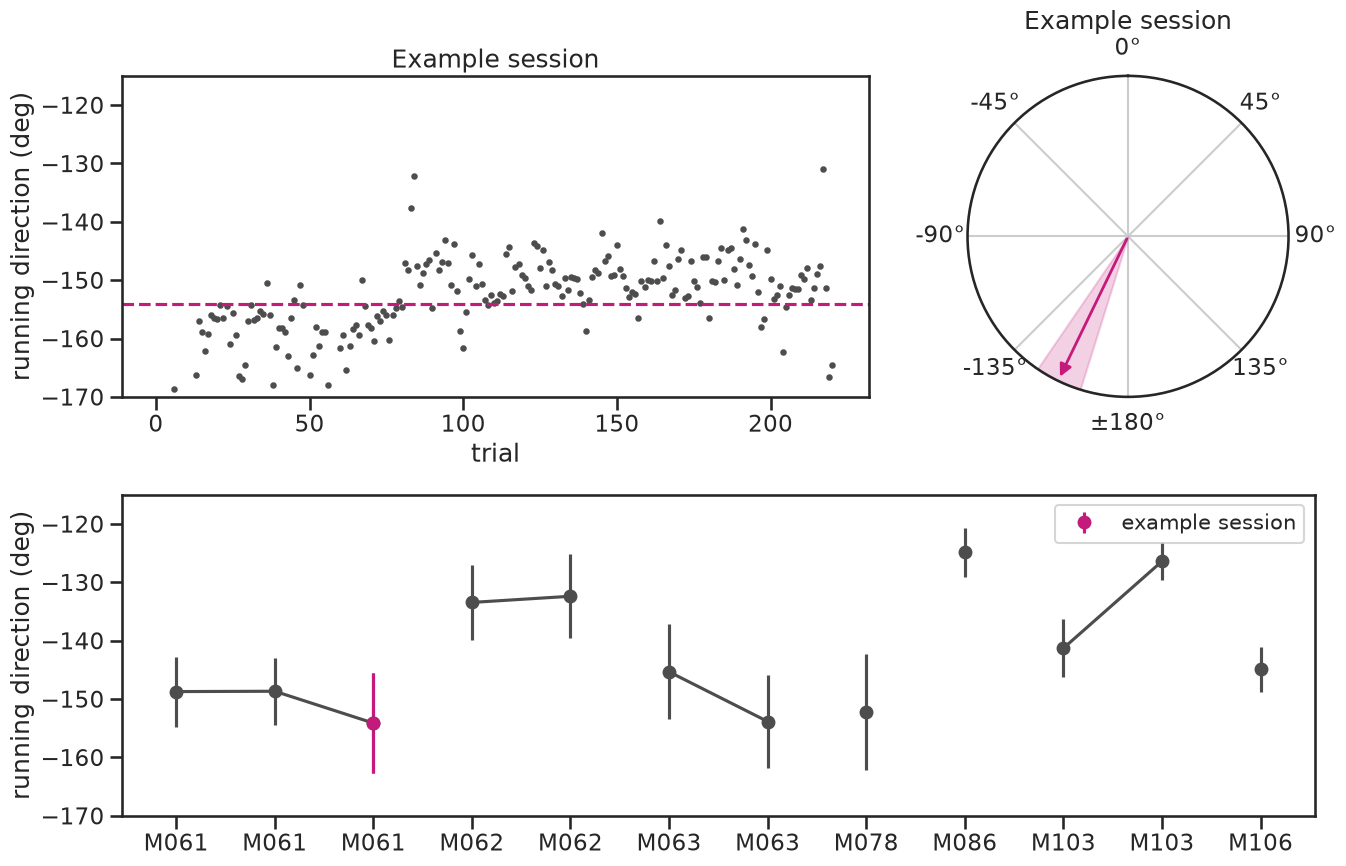

In [126]:
base = (t >= -1.5) & (t < -0.1)


def session_yaw(d):
    P = d["bhv"].reshape(len(d["bhv"]), len(t), -1, 3)
    k = list(d["bhv_keypoints"])
    rc = np.nanmean(P[:, base, k.index("shoulder_center")] - P[:, base, k.index("hip_center")], axis=1)
    return np.degrees(np.arctan2(rc[:, 0], rc[:, 2]))


def circ_stats(yaw):
    res = np.nanmean(np.exp(1j * np.radians(yaw)))
    return np.degrees(np.angle(res)), np.degrees(np.sqrt(-2 * np.log(np.abs(res)))), np.abs(res)


yaw = session_yaw(s[sess])
circ_mean, circ_std, resultant = circ_stats(yaw)

sessions = list(s)
animals = list(dict.fromkeys(k[:4] for k in s))
session_stats = [circ_stats(session_yaw(s[k])) for k in sessions]

with vizutils.apply_plot_style('talk'):

    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(2, 2, width_ratios=[2, 1])

    ax = ax_yaw = fig.add_subplot(gs[0, 0])
    ax.scatter(np.arange(len(yaw)), yaw, s=10, color=NEUTRAL)
    ax.axhline(circ_mean, color=ACCENT, ls="--")
    ax.set_xlabel("trial")
    ax.set_ylabel("running direction (deg)")
    ax.set_title('Example session')

    ax = fig.add_subplot(gs[0, 1], projection="polar")
    m = np.radians(circ_mean)
    ax.fill_between(m + np.radians(circ_std) * np.linspace(-1, 1, 50), 0, 1, color=ACCENT, alpha=0.2)
    ax.annotate("", xy=(m, resultant), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=ACCENT, lw=2))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(np.radians(np.arange(0, 360, 45)), ["0°", "45°", "90°", "135°", "±180°", "-135°", "-90°", "-45°"])
    ax.set_title('Example session')


    ax = fig.add_subplot(gs[1, :], sharey=ax_yaw)
    for a in animals:
        idx = [j for j, k in enumerate(sessions) if k.startswith(a)]
        ax.errorbar(idx, [session_stats[j][0] for j in idx], yerr=[session_stats[j][1] for j in idx],
                    fmt="-o", color=NEUTRAL, capsize=0)
    i = sessions.index(sess)
    ax.errorbar(i, session_stats[i][0], yerr=session_stats[i][1], fmt="o", color=ACCENT, capsize=0,
                label="example session")
    ax.set_xticks(range(len(sessions)), [k[:4] for k in sessions])
    ax.set_ylabel("running direction (deg)")
    ax.set_ylim(-170, -115)
    plt.tight_layout()
    ax.legend(fontsize="small", ncol=2)

    # fig.suptitle(f"{sess}: circular mean {circ_mean:+.1f} ± {circ_std:.1f}°, R={resultant:.2f}, n={len(yaw)}")
    plt.show()

## Means

<Figure size 640x480 with 0 Axes>

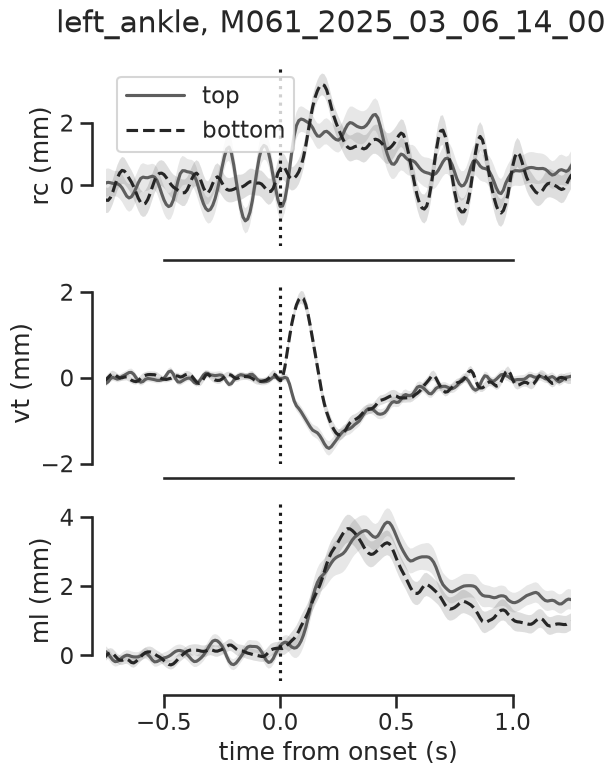

In [140]:
kp_lv = "left_ankle"
d_ = s[sess]
R_ = d_["bhv_rot"].reshape(len(d_["bhv_rot"]), len(t), -1, 3)[:, :, list(d_["bhv_keypoints"]).index(kp_lv)]

with vizutils.apply_plot_style('talk'):

    fig, axs = plt.subplots(3, 1, figsize=(6, 8), sharex=True)
    for l, style in LEVEL_STYLE.items():
        tr = R_[d_["level"] == l]
        m, sem = tr.mean(axis=0), tr.std(axis=0, ddof=1) / np.sqrt(len(tr))
        for dim, ax in enumerate(axs):
            ax.plot(t, m[:, dim], label=Params.levelcode_to_str[l], **style)
            ax.fill_between(t, m[:, dim] - sem[:, dim], m[:, dim] + sem[:, dim], color=style["color"], alpha=0.15, lw=0)
    for dim, ax in enumerate(axs):
        ax.axvline(0, color="k", ls=":")
        ax.set_ylabel(f"{['rc', 'vt', 'ml'][dim]} (mm)")
    axs[0].legend(handlelength=2.5)
    axs[0].set_xlim(-0.75, 1.25)
    axs[-1].set_xlabel("time from onset (s)")
    for ax in axs[:-1]:
        ax.tick_params(bottom=False)
    fig.suptitle(f"{kp_lv}, {sess}", y=0.95)
plt.show()

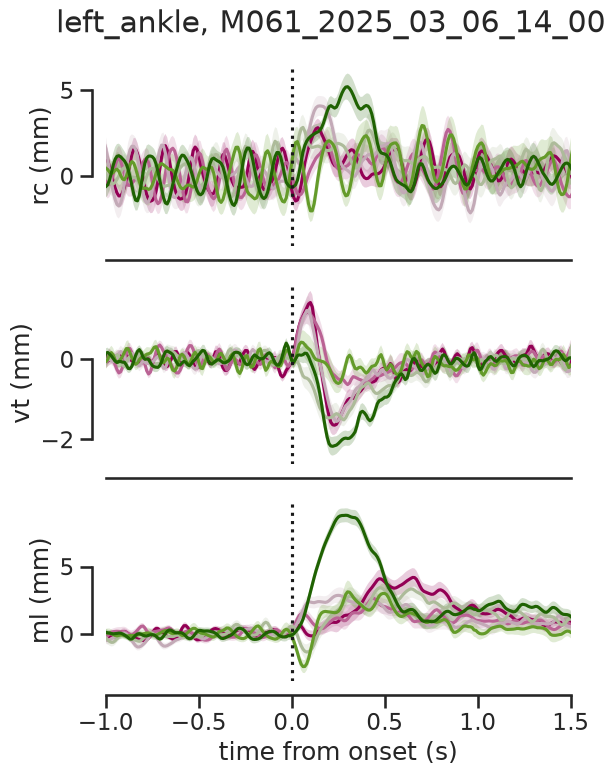

In [156]:
ang = d_["angle"]

with vizutils.apply_plot_style('talk'):

    fig, axs = plt.subplots(3, 1, figsize=(6, 8), sharex=True)
    for a, color in ANGLE_COLOR.items():
        tr = R_[ang == a]
        m, sem = tr.mean(axis=0), tr.std(axis=0, ddof=1) / np.sqrt(len(tr))
        for dim, ax in enumerate(axs):
            ax.plot(t, m[:, dim], color=color, label=f"{a}°")
            ax.fill_between(t, m[:, dim] - sem[:, dim], m[:, dim] + sem[:, dim], color=color, alpha=0.2, lw=0)
    for dim, ax in enumerate(axs):
        ax.axvline(0, color="k", ls=":")
        ax.set_ylabel(f"{['rc', 'vt', 'ml'][dim]} (mm)")
    # axs[0].legend(ncol=2)
    axs[0].set_xlim(-1, 1.5)
    axs[-1].set_xlabel("time from onset (s)")
    for ax in axs[:-1]:
        ax.tick_params(bottom=False)
    fig.suptitle(f"{kp_lv}, {sess}", y=0.95)
plt.show()

## Decoding

In [80]:
SESSIONS_DECODING = [
    "M061_2025_03_04_10_00",
    "M061_2025_03_05_14_00",
    "M061_2025_03_06_14_00",
    "M062_2025_03_20_14_00",
    "M062_2025_03_21_14_00",
    # "M063_2025_03_13_14_00",
    # "M063_2025_03_14_15_30",
    "M078_2025_08_06_15_00",
    "M086_2025_12_10_15_00",
    "M103_2026_02_18_15_30",
    # "M103_2026_02_19_15_30",  # less trials
    "M106_2026_02_25_15_00",
    # "M106_2026_02_26_16_00",  # less trials, currently no bhv
]

In [81]:
from sklearn.model_selection import StratifiedKFold

import tools.decoding as decode

DEC_CACHE = CACHE / "decoding"
DEC_CACHE.mkdir(parents=True, exist_ok=True)

TARGETS = {"level": "level", "angle": "angle", "sol_id": "codes"}
WIN, STEP, SEED = 30, 2, 0
POOL = slice(200, 300)
DIMS = ["rc", "vt", "ml"]
TAG = f"bhv_rot_w{WIN}_s{STEP}_shuf{SEED}_dims"


def decode_session(sess):
    """Decode level, angle and sol_id from one session with trial-wise cross-validated Gaussian naive Bayes, pooled and in moving windows, cached in ``DEC_CACHE``.

    Parameters
    ----------
    sess : str
        Session name, a key of ``s``.

    Returns
    -------
    dict
        Per target: ``{name}_pooled``, ``{name}_mw`` and per-dim variants.
        Also chances, ``time_end`` and ``n_trials``.
    """
    f = DEC_CACHE / f"{sess}_{TAG}.npz"
    if f.exists():
        return dict(np.load(f))
    d = s[sess]
    X = d["bhv_rot"]
    assert np.isfinite(X).all(), f"{sess}: non-finite values in bhv_rot"
    out = {"n_trials": len(X)}
    feats = {None: X, **{dim: X[:, :, i::3] for i, dim in enumerate(DIMS)}}
    for name, field in TARGETS.items():
        y = d[field]
        counts = np.unique(y, return_counts=True)[1]
        folds = min(5, counts.min())
        assert folds >= 2, f"{sess}: a {name} class has {counts.min()} trial(s)"
        cv = StratifiedKFold(folds, shuffle=True, random_state=SEED)
        out[f"{name}_n_splits"] = folds
        out[f"{name}_chance_uniform"] = 1 / len(counts)
        out[f"{name}_chance_majority"] = counts.max() / len(y)
        for dim, Xf in feats.items():
            key = name if dim is None else f"{name}_{dim}"
            out[f"{key}_pooled"], _ = decode.moving_window_decoding(
                Xf[:, POOL], y, window_length_bin=POOL.stop - POOL.start, step_bin=1, cv=cv
            )
            out[f"{key}_mw"], tp = decode.moving_window_decoding(
                Xf, y, window_length_bin=WIN, step_bin=STEP, cv=cv
            )
    out["time_end"] = tp - 200 * 0.01
    np.savez(f, **out)
    return out


dec = {sess: decode_session(sess) for sess in SESSIONS_DECODING}

for name in TARGETS:
    acc = np.array([dec[k][f"{name}_pooled"].mean() for k in dec])
    chance = np.array([dec[k][f"{name}_chance_majority"] for k in dec])
    print(f"{name}: pooled accuracy median {np.median(acc):.2f} "
          f"(range {acc.min():.2f}-{acc.max():.2f}), chance median {np.median(chance):.2f}, "
          f"above chance in {(acc > chance).sum()}/{len(acc)} sessions")
    for dim in DIMS:
        acc_d = np.array([dec[k][f"{name}_{dim}_pooled"].mean() for k in dec])
        print(f"    {dim} only: median {np.median(acc_d):.2f} (range {acc_d.min():.2f}-{acc_d.max():.2f})")

100%|██████████| 186/186 [00:02<00:00, 83.36it/s]

level: pooled accuracy median 0.73 (range 0.67-0.80), chance median 0.53, above chance in 9/9 sessions
    rc only: median 0.57 (range 0.51-0.65)
    vt only: median 0.81 (range 0.74-0.86)
    ml only: median 0.62 (range 0.45-0.65)
angle: pooled accuracy median 0.41 (range 0.36-0.55), chance median 0.20, above chance in 9/9 sessions
    rc only: median 0.35 (range 0.25-0.46)
    vt only: median 0.38 (range 0.24-0.47)
    ml only: median 0.38 (range 0.30-0.56)
sol_id: pooled accuracy median 0.36 (range 0.27-0.50), chance median 0.12, above chance in 9/9 sessions
    rc only: median 0.22 (range 0.17-0.37)
    vt only: median 0.36 (range 0.28-0.47)
    ml only: median 0.31 (range 0.20-0.48)


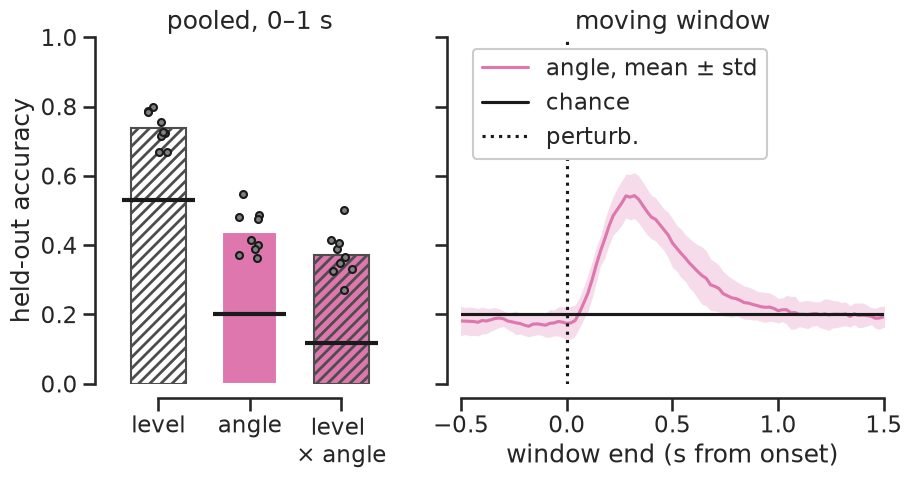

In [82]:
dec = {k: dict(np.load(DEC_CACHE / f"{k}_{TAG}.npz")) for k in SESSIONS_DECODING}
t_end = dec[SESSIONS_DECODING[0]]["time_end"]
names = list(TARGETS)
rng = np.random.default_rng(0)

bar_style = {
    "angle": bhv.FACTOR_BAR["angle"],
    "level": {**bhv.FACTOR_BAR["level"], "edgecolor": NEUTRAL},
    "sol_id": {**bhv.FACTOR_BAR["level×angle"], "edgecolor": NEUTRAL},
}
line_style = {
    "angle": bhv.FACTOR_LINE["angle"],
    "level": {**bhv.FACTOR_LINE["level"], "color": NEUTRAL},
    "sol_id": bhv.FACTOR_LINE["level×angle"],
}
label = {"level": "level", "angle": "angle", "sol_id": "level × angle"}

mw_names = ["angle"]

with vizutils.apply_plot_style('talk'), plt.rc_context({"hatch.linewidth": 2}):

    fig = plt.figure(figsize=(10, max(4.5, 2 * len(mw_names))))
    gs = fig.add_gridspec(len(mw_names), 2, width_ratios=[2, 3])

    ax = ax_bar = fig.add_subplot(gs[:, 0])
    for j, name in enumerate(names):
        acc = np.array([dec[k][f"{name}_pooled"].mean() for k in dec])
        chance = np.median([dec[k][f"{name}_chance_majority"] for k in dec])
        ax.bar(j, acc.mean(), width=0.6, lw=1.5, **bar_style[name])
        ax.scatter(j + rng.uniform(-0.12, 0.12, len(acc)), acc, facecolor='0.5', edgecolor='k', alpha=1, s=25, zorder=3)
        ax.hlines(chance, j - 0.4, j + 0.4, color="k", lw=3, zorder=4)
    ax.set_xticks(range(len(names)), [label[n].replace(" × ", " \n× ") for n in names])
    ax.set_ylabel("held-out accuracy")
    ax.set_ylim(0, 1)
    ax.set_title("pooled, 0–1 s")

    axs = [fig.add_subplot(gs[0, 1], sharey=ax_bar)]
    axs += [fig.add_subplot(gs[i, 1], sharex=axs[0], sharey=ax_bar) for i in range(1, len(mw_names))]
    for ax, name in zip(axs, mw_names):
        acc = np.array([dec[k][f"{name}_mw"].mean(axis=1) for k in dec])
        chance = np.median([dec[k][f"{name}_chance_majority"] for k in dec])
        m, std = acc.mean(axis=0), acc.std(axis=0, ddof=1)
        ax.fill_between(t_end, m - std, m + std, color=line_style[name]["color"], alpha=0.25, lw=0)
        ax.plot(t_end, m, label=f"{label[name]}, mean ± std", **line_style[name])
        ax.axhline(chance, color="k", label="chance")
        ax.axvline(0, color="k", ls=":", label="perturb.")
        # ax.set_ylabel(label[name])
    axs[0].set_title("moving window")
    axs[0].set_xlim(-0.5, 1.5)
    axs[-1].set_xlabel("window end (s from onset)")
    for ax in axs:
        ax.tick_params(labelleft=False)
    for ax in axs[:-1]:
        ax.tick_params(bottom=False, labelbottom=False)
    axs[0].legend(loc="upper left", frameon=True, framealpha=1, facecolor="white")
# plt.tight_layout()
plt.show()

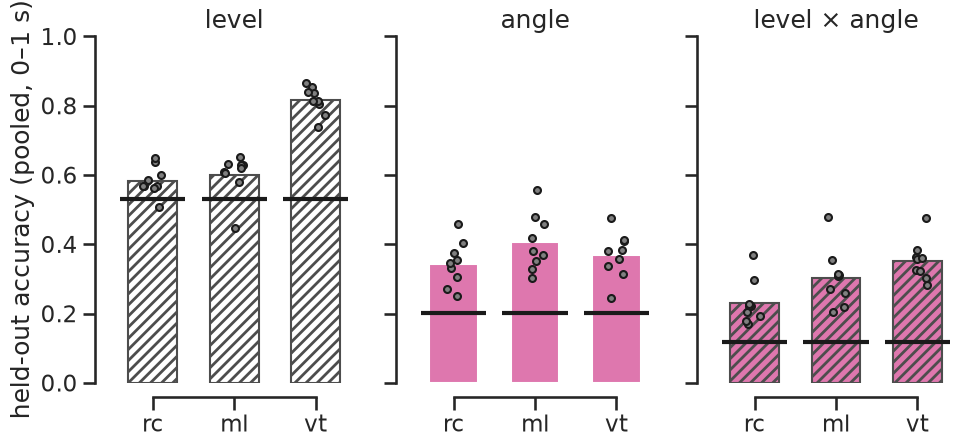

In [85]:
dec = {k: dict(np.load(DEC_CACHE / f"{k}_{TAG}.npz")) for k in SESSIONS_DECODING}
names = list(TARGETS)
dims = ["rc", "ml", "vt"]
rng = np.random.default_rng(0)

bar_style = {
    "angle": bhv.FACTOR_BAR["angle"],
    "level": {**bhv.FACTOR_BAR["level"], "edgecolor": NEUTRAL},
    "sol_id": {**bhv.FACTOR_BAR["level×angle"], "edgecolor": NEUTRAL},
}
label = {"level": "level", "angle": "angle", "sol_id": "level × angle"}

with vizutils.apply_plot_style('talk'), plt.rc_context({"hatch.linewidth": 2}):

    fig, axs = plt.subplots(1, len(names), figsize=(11, 4.5), sharey=True)
    for ax, name in zip(axs, names):
        chance = np.median([dec[k][f"{name}_chance_majority"] for k in dec])
        for j, dim in enumerate(dims):
            acc = np.array([dec[k][f"{name}_{dim}_pooled"].mean() for k in dec])
            ax.bar(j, acc.mean(), width=0.6, lw=1.5, **bar_style[name])
            ax.scatter(j + rng.uniform(-0.12, 0.12, len(acc)), acc, facecolor="0.5", edgecolor="k", s=25, zorder=3)
            ax.hlines(chance, j - 0.4, j + 0.4, color="k", lw=3, zorder=4)
        ax.set_xticks(range(len(dims)), dims)
        ax.set_title(label[name])
    axs[0].set_ylabel("held-out accuracy (pooled, 0–1 s)")
    axs[0].set_ylim(0, 1)
    for ax in axs[1:]:
        ax.tick_params(labelleft=False)

plt.show()

## Colour palette

Shared colour conventions for this and later results sections (incl. dPCA re-plots). Two kinds of colour:

**1. Per-condition colours (one line per angle / level).**
- **Angle → PiYG-cyclic colormap.** PiYG runs dark magenta → white → dark green. We wrap it into a circle with
  a short dark *bridge* from green back to magenta, centred at 180° (straight behind the animal), where no
  solenoid sits — so every sampled angle comes from PiYG itself. Orientation: dark end at the **front**
  (0° = nose), white end at the **back**; magenta = animal's **right** (ipsi: 30/90/150), green = **left**
  (contra: 210/270/330). So *hue = side*, *lightness = front → back*, and mirror pairs share lightness.
- **Why the L\* squeeze.** Raw PiYG samples near the white point (150°, 210°) come out at L\* ≈ 92–95 and vanish
  on a white background. We linearly remap the six samples' CIELAB lightness into 30–74, keeping their hue.
- **Level → line style**, not colour: solid = top, dashed = bottom. Colour stays free for angle, so
  angle × level reads as colour × style in one panel.

**2. Per-factor colours (e.g. variance share per dPCA marginalization).**
- time (condition-independent) = dark grey · angle = pink (PiYG 0.2) · level = hatched / dashed / hollow
  · level × angle = pink + hatched / dashed / hollow.
- Time is *dark* grey rather than light grey because, for red–green colour-blind readers, the pink turns
  grey-blue and would merge with a light grey.
- Caveat: the factor pink lies on the right-side angle ramp (between 90° and 150°). Keep factor colours and
  per-angle colours in separate panels/legends.

The palette itself (`ANGLE_COLOR`, `LEVEL_STYLE`, `FACTOR_*`, and the colour helpers) is defined in `bhv.py`; the cell below only previews it.
Previews and the exploration that led here: `ACROSS_SESSION_RESULTS_DIR / "bhv-001" / "palette-preview"`.

ANGLE_COLOR = {30: '#930055', 90: '#ba6394', 150: '#c3aab7', 210: '#adbb9a', 270: '#649b2a', 330: '#1f6202'}
FACTOR_COLOR = {'time': '#4d4d4d', 'angle': '#de77ae', 'level': '#262626'}


<Figure size 640x480 with 0 Axes>

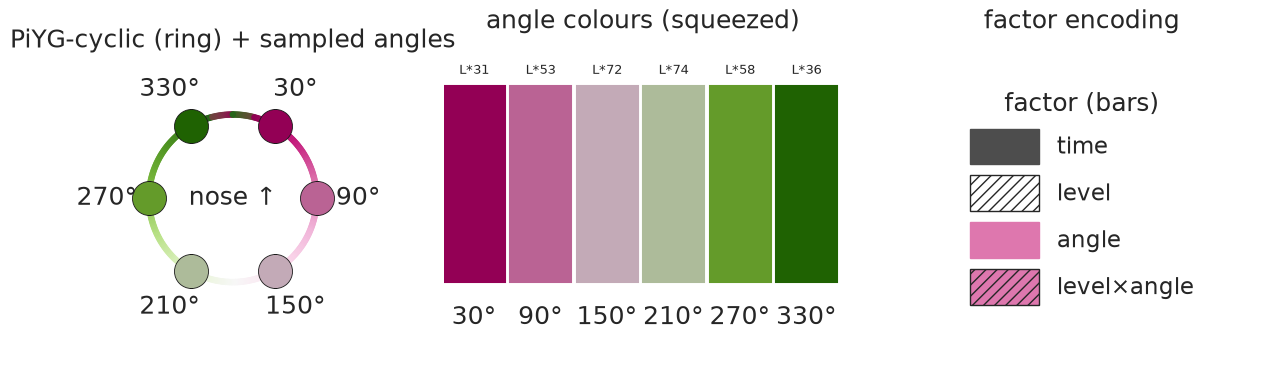

In [147]:
from matplotlib.patches import Patch, Rectangle

from bhv import ANGLES, FACTOR_BAR, piyg_cyclic_at, to_lab

# preview: wheel around the animal, swatches with lightness, factor key
with vizutils.apply_plot_style('talk'):
    fig = plt.figure(figsize=(15, 4.2))
    gs_ = fig.add_gridspec(1, 3, width_ratios=[1, 1.4, 1.2])
    ax = fig.add_subplot(gs_[1])
    for j, a in enumerate(ANGLES):
        ax.add_patch(Rectangle((j, 0), 0.92, 1, color=ANGLE_COLOR[a]))
        ax.text(j + 0.46, -0.12, f"{a}°", ha="center", va="top")
        ax.text(j + 0.46, 1.06, f"L*{to_lab(ANGLE_COLOR[a])[0]:.0f}", ha="center", fontsize=9)
    ax.set_xlim(0, 6); ax.set_ylim(-0.4, 1.25); ax.set_title("angle colours (squeezed)")
    ax = fig.add_subplot(gs_[2])
    handles = [Patch(label=k, lw=1, **v) for k, v in FACTOR_BAR.items()]
    ax.legend(handles=handles, loc="center", frameon=False, title="factor (bars)", handleheight=2, handlelength=3)
    ax.set_title("factor encoding")
    for ax in fig.axes[-2:]:
        ax.axis("off")
    ax = fig.add_subplot(gs_[0], projection="polar")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    th = np.linspace(0, 360, 361)
    ax.scatter(np.radians(th), np.ones_like(th), c=[piyg_cyclic_at(x) for x in th], s=10)
    for a in ANGLES:
        ax.scatter(np.radians(a), 1, s=600, color=ANGLE_COLOR[a], edgecolor="k", lw=0.6, zorder=3)
        ax.text(np.radians(a), 1.5, f"{a}°", ha="center", va="center", )
    ax.text(0, 0, "nose ↑", ha="center", va="center")
    ax.set_ylim(0, 1.7); ax.set_yticks([]); ax.set_xticks([]); ax.spines["polar"].set_visible(False)
    ax.set_title("PiYG-cyclic (ring) + sampled angles")
    plt.show()